## Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv("manga_dataset.csv")

In [3]:
data.head()

,mal_id,title,title_english,title_japanese,type,chapters,volumes,status,publishing,published_from,...,popularity,members,favorites,authors,serializations,genres,themes,demographics,synopsis,image_url
0,1,Monster,Monster,MONSTER,Manga,162.0,18.0,Finished,False,1994-12-05,...,27,288956,23729,"Urasawa, Naoki",Big Comic Original,Award Winning|Drama|Mystery,Adult Cast|Psychological,Seinen,"Kenzou Tenma, a renowned Japanese neurosurgeon...",https://myanimelist.net/images/manga/3/258224.jpg
1,2,Berserk,Berserk,ベルセルク,Manga,NaN,NaN,Publishing,True,1989-08-25,...,1,794592,137638,"Miura, Kentarou|Studio Gaga",Young Animal,Action|Adventure|Award Winning|Drama|Fantasy|H...,Gore|Military|Psychological,Seinen,"Guts, a former mercenary now known as the Blac...",https://myanimelist.net/images/manga/1/157897.jpg
2,3,20th Century Boys,20th Century Boys,20世紀少年,Manga,249.0,22.0,Finished,False,1999-09-27,...,24,310161,23009,"Urasawa, Naoki",Big Comic Spirits,Award Winning|Drama|Mystery|Sci-Fi,Historical|Psychological,Seinen,"As the 20th century approaches its end, people...",https://myanimelist.net/images/manga/5/260006.jpg
3,4,Yokohama Kaidashi Kikou,Yokohama Kaidashi Kikou,ヨコハマ買い出し紀行,Manga,142.0,14.0,Finished,False,1994-04-25,...,209,85859,5593,"Ashinano, Hitoshi",Afternoon,Award Winning|Sci-Fi|Slice of Life,Iyashikei,Seinen,In a post-apocalyptic world where an environme...,https://myanimelist.net/images/manga/1/171813.jpg
4,7,Hajime no Ippo,Hajime no Ippo: Fighting Spirit!,はじめの一歩,Manga,NaN,NaN,Publishing,True,1989-09-27,...,160,102198,7654,"Morikawa, George",Shounen Magazine (Weekly),Award Winning|Sports,Combat Sports,Shounen,Makunouchi Ippo is a 16-year-old high school s...,https://myanimelist.net/images/manga/2/250313.jpg


In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 82889 entries, 0 to 82888
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   mal_id          82889 non-null  int64  
 1   title           82889 non-null  str    
 2   title_english   28380 non-null  str    
 3   title_japanese  81880 non-null  str    
 4   type            82889 non-null  str    
 5   chapters        58417 non-null  float64
 6   volumes         57404 non-null  float64
 7   status          82889 non-null  str    
 8   publishing      82889 non-null  bool   
 9   published_from  81191 non-null  str    
 10  published_to    42740 non-null  str    
 11  score           30669 non-null  float64
 12  scored_by       30669 non-null  float64
 13  rank            57364 non-null  float64
 14  popularity      82889 non-null  int64  
 15  members         82889 non-null  int64  
 16  favorites       82889 non-null  int64  
 17  authors         82403 non-null  str    
 1

In [5]:
data.describe()

,mal_id,chapters,volumes,score,scored_by,rank,popularity,members,favorites
count,82889.000000,58417.000000,57404.000000,30669.000000,30669.000000,57364.000000,82889.000000,82889.000000,82889.000000
mean,98274.459289,23.685092,2.952477,6.907898,1802.598911,28624.610121,41376.504808,1828.427668,50.236955
std,58965.124155,54.286134,4.662702,0.536950,9572.093952,16545.663267,23901.134747,11913.921520,1059.858167
min,1.000000,1.000000,1.000000,2.470000,100.000000,1.000000,1.000000,2.000000,0.000000
25%,45031.000000,6.000000,1.000000,6.570000,202.000000,14293.750000,20679.000000,68.000000,0.000000
50%,102119.000000,9.000000,1.000000,6.870000,408.000000,28599.000000,41357.000000,200.000000,0.000000
75%,150119.000000,23.000000,3.000000,7.220000,1049.000000,42955.000000,62066.000000,811.000000,2.000000
max,192804.000000,6477.000000,200.000000,9.460000,442227.000000,57302.000000,82854.000000,794592.000000,137638.000000


In [6]:
# Drop kolom yang tidak dipakai
drop_cols = ['mal_id', 'title', 'title_english', 'title_japanese', 'synopsis', 'image_url', 'published_from', 'published_to']
data = data.drop(columns=drop_cols)

# Isi NaN dan PAKSA semua kolom non-angka jadi string ('str')
for col in data.columns:
    if pd.api.types.is_numeric_dtype(data[col]):
        data[col] = data[col].fillna(data[col].median())
    else:
        data[col] = data[col].astype(str).fillna('Unknown')

In [7]:
# Mengambil kolom numerikal
numerical_features = [feature for feature in data.columns if data[feature].dtypes != 'str']
print("Jumlah fitur numerik = ", len(numerical_features))
print("Daftar fitur numerik = ", numerical_features)
display(data[numerical_features].head())

Jumlah fitur numerik =  9
Daftar fitur numerik =  ['chapters', 'volumes', 'publishing', 'score', 'scored_by', 'rank', 'popularity', 'members', 'favorites']


,chapters,volumes,publishing,score,scored_by,rank,popularity,members,favorites
0,162.0,18.0,False,9.16,116668.0,6.0,27,288956,23729
1,9.0,1.0,True,9.46,397810.0,1.0,1,794592,137638
2,249.0,22.0,False,8.93,109324.0,22.0,24,310161,23009
3,142.0,14.0,False,8.66,21458.0,88.0,209,85859,5593
4,9.0,1.0,True,8.76,42178.0,57.0,160,102198,7654


In [8]:
# Mengambil kolom kategorikal (Ganti 'O' jadi 'str')
categorical_features = [feature for feature in data.columns if data[feature].dtypes == 'str']
print("Jumlah fitur kategorikal = ", len(categorical_features))
print("Daftar fitur kategorikal = ", categorical_features)
display(data[categorical_features].head())

Jumlah fitur kategorikal =  7
Daftar fitur kategorikal =  ['type', 'status', 'authors', 'serializations', 'genres', 'themes', 'demographics']


,type,status,authors,serializations,genres,themes,demographics
0,Manga,Finished,"Urasawa, Naoki",Big Comic Original,Award Winning|Drama|Mystery,Adult Cast|Psychological,Seinen
1,Manga,Publishing,"Miura, Kentarou|Studio Gaga",Young Animal,Action|Adventure|Award Winning|Drama|Fantasy|H...,Gore|Military|Psychological,Seinen
2,Manga,Finished,"Urasawa, Naoki",Big Comic Spirits,Award Winning|Drama|Mystery|Sci-Fi,Historical|Psychological,Seinen
3,Manga,Finished,"Ashinano, Hitoshi",Afternoon,Award Winning|Sci-Fi|Slice of Life,Iyashikei,Seinen
4,Manga,Publishing,"Morikawa, George",Shounen Magazine (Weekly),Award Winning|Sports,Combat Sports,Shounen


In [9]:
from sklearn.preprocessing import LabelEncoder

# Panggil LabelEncoder khusus buat 'status'
le_status = LabelEncoder()
# Fit ke data asli (sebelum di-encode) biar keliatan urutannya
le_status.fit(data['status'].astype(str)) # Pastikan pakai data asli yang belum di-encode

# Print hasilnya
for index, label in enumerate(le_status.classes_):
    print(f"Angka {index} = {label}")

Angka 0 = Discontinued
Angka 1 = Finished
Angka 2 = On Hiatus
Angka 3 = Publishing


In [10]:
# Mengubah kolom kategorikal menjadi angka untuk klasifikasi
from sklearn.preprocessing import LabelEncoder

for feature in categorical_features:
    le = LabelEncoder()
    # Paksa jadi string (.astype(str)) biar error 'Manga' gak muncul lagi
    data[feature] = le.fit_transform(data[feature].astype(str))
    
    # Opsional: print buat mastiin udah berubah
    # print(f"{feature} berhasil di-encode")

In [11]:
data.head()

,type,chapters,volumes,status,publishing,score,scored_by,rank,popularity,members,favorites,authors,serializations,genres,themes,demographics
0,2,162.0,18.0,1,False,9.16,116668.0,6.0,27,288956,23729,36585,122,914,140,8
1,2,9.0,1.0,3,True,9.46,397810.0,1.0,1,794592,137638,20911,1341,9,583,8
2,2,249.0,22.0,1,False,8.93,109324.0,22.0,24,310161,23009,36585,124,916,795,8
3,2,142.0,14.0,1,False,8.66,21458.0,88.0,209,85859,5593,2726,28,951,948,8
4,2,9.0,1.0,3,True,8.76,42178.0,57.0,160,102198,7654,21959,1183,954,321,13


In [12]:
# Mengambil kolom untuk fitur dan Label
x = data.drop(['status'], axis=1)
y = data['status']

print(x.head())
print(y.head())

   type  chapters  volumes  publishing  score  scored_by  rank  popularity  \
0     2     162.0     18.0       False   9.16   116668.0   6.0          27   
1     2       9.0      1.0        True   9.46   397810.0   1.0           1   
2     2     249.0     22.0       False   8.93   109324.0  22.0          24   
3     2     142.0     14.0       False   8.66    21458.0  88.0         209   
4     2       9.0      1.0        True   8.76    42178.0  57.0         160   

   members  favorites  authors  serializations  genres  themes  demographics  
0   288956      23729    36585             122     914     140             8  
1   794592     137638    20911            1341       9     583             8  
2   310161      23009    36585             124     916     795             8  
3    85859       5593     2726              28     951     948             8  
4   102198       7654    21959            1183     954     321            13  
0    1
1    3
2    1
3    1
4    3
Name: status, dtype: i

In [13]:
# membagi data menjadi data test dan data latih
from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size = 0.25, random_state = 0)

In [14]:
# melatih model Gaussian Naive Bayes
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(x_train, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](4,)","[ 157.,51764., 315., 9930.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](4,)","[0. ,0.83,0.01,0.16]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](4,)","[0,1,2,3]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.5715
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](15,)","['type','chapters','volumes',...,'genres','themes','demographics']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,15
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](4, 15)","[[ 2.55, 30.42, 2.39,...,1095.39,1097.64, 13.15], [ 2.34, 21.09, 2.61,...,1357.7 ,1256.61, 12.04], [ 2.18, 33.74, 3.84,...,1101.81,1172.07, 11.9 ], [ 2.16, 9. , 1. ,...,1208.96,1151.86, 12.34]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](4, 15)","[[ 1.55, 1324.48, 13.78,...,364747.04,168811.35, 4.14], [ 2.68, 1716.31, 17.95,...,234918.13, 92609.9 , 13.66], [ 1.48, 4691.45, 62.2 ,...,312931.45,127714.79, 12.47], [ 1.47, 0.57, 0.57,...,302027.07,142001.27, 11.55]]"


In [15]:
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Evaluasi Training
[[   28   104     5    20]
 [ 2000 36263  1124 12377]
 [   35   225    10    45]
 [    0     0    55  9875]]
              precision    recall  f1-score   support

           0       0.01      0.18      0.03       157
           1       0.99      0.70      0.82     51764
           2       0.01      0.03      0.01       315
           3       0.44      0.99      0.61      9930

    accuracy                           0.74     62166
   macro avg       0.36      0.48      0.37     62166
weighted avg       0.90      0.74      0.78     62166



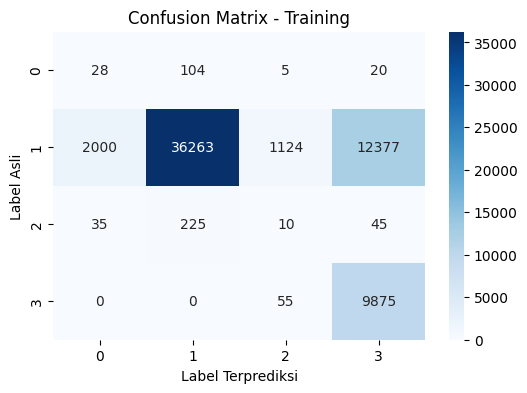

In [16]:
# Evaluasi Training
from sklearn.metrics import confusion_matrix, classification_report

print("Evaluasi Training")
cm_train = confusion_matrix(y_train, y_pred_train)
print(cm_train)
print(classification_report(y_train, y_pred_train))

plt.figure(figsize = (6, 4))
sns.heatmap(cm_train, annot = True, fmt='d', cmap = 'Blues', xticklabels = np.unique(y), yticklabels = np.unique(y))
plt.title("Confusion Matrix - Training")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show()

Evaluasi Testing
[[    7    38     5     8]
 [  705 12081   330  4048]
 [   10    72     6    23]
 [    0     1    14  3375]]
              precision    recall  f1-score   support

           0       0.01      0.12      0.02        58
           1       0.99      0.70      0.82     17164
           2       0.02      0.05      0.03       111
           3       0.45      1.00      0.62      3390

    accuracy                           0.75     20723
   macro avg       0.37      0.47      0.37     20723
weighted avg       0.89      0.75      0.78     20723



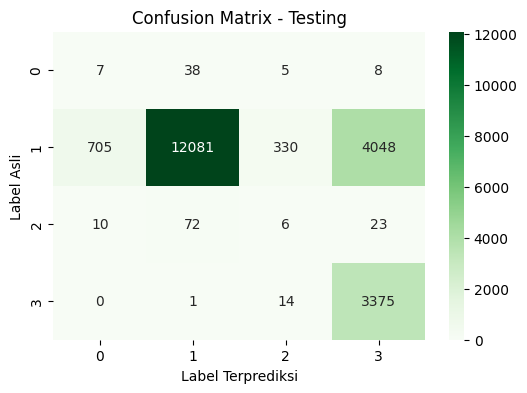

In [17]:
# Maftuh Faisal_202431163
from sklearn.metrics import confusion_matrix, classification_report

print("Evaluasi Testing")
cm_test = confusion_matrix(y_test, y_pred_test)
print(cm_test)
print(classification_report(y_test, y_pred_test))

plt.figure(figsize = (6, 4))
sns.heatmap(cm_test, annot = True, fmt='d', cmap = 'Greens', xticklabels = np.unique(y), yticklabels = np.unique(y))
plt.title("Confusion Matrix - Testing")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show()

In [18]:
# Uji prediksi 1 data baru (ambil nilai median / modus dari data asli)
new_data = {}
for col in x.columns:
    if col in numerical_features:
        new_data[col] = [data[col].median()]
    else:
        new_data[col] = [data[col].mode()[0]]

new_df = pd.DataFrame(new_data)
prediction = model.predict(new_df)
print("Hasil Prediksi Data Baru:", prediction[0])

Hasil Prediksi Data Baru: 3
